# UTS Graf Sains Data: Rekomendasi Item dengan Graf Neo4j (RetailRocket)

**Nama:** Rizqi Wahyu Gusniadi &nbsp;·&nbsp; **NIM:** 24031554203 &nbsp;·&nbsp; **Program studi:** S1 Sains Data, Universitas Negeri Surabaya &nbsp;·&nbsp; **Mata kuliah:** Graf Sains Data

**Dataset:** RetailRocket e-commerce (Roman Zykov, Kaggle), `events.csv` berisi 2.756.101 baris interaksi, 3 Mei sampai 18 September 2015.
**Periode yang ditetapkan:** **P1 (training) = 18–31 Mei 2015** dan **P2 (testing) = 16–31 Juli 2015** (UTC, batas akhir inklusif).

## Peta jawaban

| Soal | Bagian notebook |
|---|---|
| 2.1 no. 1 | Menentukan dua periode dan memfilter data |
| 2.1 no. 2 | Menyimpan hasil filter ke `events_P1.csv` dan `events_P2.csv` |
| 2.1 no. 3 | Impor P1 ke Neo4j, komposisi subgraf, penjelasan Cypher |
| 2.1 no. 4 dan 5 | VSM User dan VSM Item (karakteristik, plot networkx) |
| 2.1 no. 6 | Proyeksi yang lebih baik: Item–Item |
| 2.1 no. 7 | Similarity (cosine) pada proyeksi Item–Item dengan Python |
| 2.1 no. 7a | Cypher untuk 5 record dengan similarity tertinggi |
| 2.1 no. 7b | Menuliskan similarity ke graf dan menampilkan hasil query |
| 2.1 no. 8 | Cypher dan graf sebelum dan sesudah perhitungan similarity |
| 2.2 no. 1a dan 1b | Skrip KNN, 3 item yang diiklankan (k = 5) |
| 2.2 no. 2a dan 2b | Hit@5 dan NDCG@5 |

## Keputusan desain (dipakai konsisten di seluruh notebook)

1. **Hanya P1 yang dimuat ke Neo4j.** P2 hanya dipakai sebagai data uji (ground truth) di 2.2, supaya rekomendasi tidak "mengintip" jawabannya.
2. **Bobot interaksi:** `VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5 (membeli sinyal minat yang lebih kuat daripada melihat). Bobot satu pasangan user–item adalah jumlah bobot semua interaksinya. Bobot ini pilihan desain, bukan ketentuan soal.
3. **Proyeksi dan similarity:** proyeksi Item–Item (alasan di no. 6) dengan cosine similarity.
4. **Rekomendasi:** KNN **item-based**, k = 5 (konsisten dengan proyeksi Item–Item).
5. **Reproduksibilitas:** semua pemilihan bersifat deterministik (item acuan = item terpopuler, user acak memakai `numpy.random.default_rng(42)`, aturan seri diurutkan berdasarkan ID).

**Cara menjalankan ulang:** letakkan `events.csv` di folder `data/`, pilih kernel dari environment yang berisi paket pada `requirements.txt`, pastikan Neo4j berjalan, lalu *Run All* dan isi password Neo4j saat diminta. Kalau database sudah berisi graf dari proses sebelumnya, ubah `RESET_GRAPH = True` pada sel reset (bagian no. 3) agar graf dikosongkan terlebih dahulu.

## 2.1 Wrangling dan EDA

### No. 1: Menentukan dua periode waktu

Dua periode yang ditetapkan untuk saya: **P1 (fold training) = 18–31 Mei 2015** dan **P2 (fold testing) = 16–31 Juli 2015**.

- Kolom `timestamp` pada RetailRocket berisi unix epoch dalam milidetik (bukan detik), sehingga dikonversi dengan `pd.to_datetime(..., unit="ms")` dalam zona waktu UTC.
- Batas akhir bersifat inklusif: filter memakai rentang `[tanggal mulai, tanggal akhir + 1 hari)`, sehingga 31 Mei dan 31 Juli ikut terhitung.
- Kedua periode berada di dalam rentang data (3 Mei – 18 September 2015), tidak saling tumpang tindih, dan P2 terjadi setelah P1 (tidak ada kebocoran data dari masa depan ke training).

Sel berikut hanya menyimpan konfigurasi periode (satu-satunya bagian yang perlu diganti kalau periodenya berubah).

In [1]:
import pandas as pd
from IPython.display import display   # dipakai oleh display() pada bagian 2.2

P1_START, P1_END = "2015-05-18", "2015-05-31"   # Fold training (P1)
P2_START, P2_END = "2015-07-16", "2015-07-31"   # Fold testing (P2)

Fungsi `slice_period` membaca `events.csv`, mengubah `timestamp` menjadi waktu (`dt`), lalu mengambil baris yang jatuh pada rentang periode. Kolom bantu `dt` dibuang setelahnya sehingga skema data sama dengan `events.csv` asli.

In [2]:
df = pd.read_csv("data/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")   # UTC

def slice_period(df, start, end):
    s = pd.Timestamp(start)
    e = pd.Timestamp(end) + pd.Timedelta(days=1)   # batas akhir inklusif
    return df[(df["dt"] >= s) & (df["dt"] < e)].drop(columns="dt")

p1 = slice_period(df, P1_START, P1_END)
p2 = slice_period(df, P2_START, P2_END)

### No. 2: Menyimpan hasil filter ke file .csv

Hasil filter disimpan sebagai `data/events_P1.csv` (training) dan `data/events_P2.csv` (testing).

In [3]:
p1.to_csv("data/events_P1.csv", index=False)
p2.to_csv("data/events_P2.csv", index=False)

Ringkasan kedua periode, dan jumlah visitor yang muncul di kedua periode (`irisan`), karena evaluasi di 2.2 hanya bisa dilakukan untuk user yang ada di P1 sekaligus P2.

In [4]:
for nama, d in [("P1", p1), ("P2", p2)]:
    print(nama, "| baris:", len(d), "| visitor:", d.visitorid.nunique(), "| item:", d.itemid.nunique())
    print(d.event.value_counts().to_dict())

irisan = set(p1.visitorid) & set(p2.visitorid)
print("Visitor yang ada di P1 DAN P2:", len(irisan))

P1 | baris: 294333 | visitor: 159344 | item: 78812
{'view': 285187, 'addtocart': 6939, 'transaction': 2207}
P2 | baris: 364206 | visitor: 199899 | item: 88699
{'view': 351830, 'addtocart': 9263, 'transaction': 3113}
Visitor yang ada di P1 DAN P2: 2779


**Hasil**

| | Baris | Visitor | Item | view | addtocart | transaction |
|---|---|---|---|---|---|---|
| **P1** (18–31 Mei) | 294.333 | 159.344 | 78.812 | 285.187 | 6.939 | 2.207 |
| **P2** (16–31 Juli) | 364.206 | 199.899 | 88.699 | 351.830 | 9.263 | 3.113 |

Jumlah event per jenis menjumlah tepat ke total baris di kedua periode. Hanya 2.779 visitor (1,7% dari visitor P1) yang muncul di P1 dan P2 sekaligus. Angka kecil ini menjadi batas kemampuan evaluasi di 2.2 (dibahas lagi pada kesimpulan).

### No. 3: Impor P1 ke Neo4j dan komposisi subgraf

**Model graf (hanya data P1):**

- Simpul `(:Visitor {visitorId})` dan `(:Item {itemId})`
- Relasi `(:Visitor)-[:VIEWED {timestamp}]->(:Item)`, `(:Visitor)-[:ADDED_TO_CART {timestamp}]->(:Item)`, dan `(:Visitor)-[:BOUGHT {timestamp, transactionId}]->(:Item)`

P2 sengaja tidak dimuat ke graf: P2 hanya dipakai sebagai ground truth di 2.2, agar rekomendasi tidak melihat jawabannya.

Urutan langkah: koneksi, reset opsional, constraint, impor batch, lalu query komposisi.

**Koneksi.** Password dimasukkan lewat `getpass` sehingga tidak tersimpan di notebook. `execute_query` membutuhkan driver Neo4j versi 5 ke atas.

In [5]:
import getpass
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
DATABASE = "neo4j"
PASSWORD = getpass.getpass("Password Neo4j: ")

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
driver.verify_connectivity()
print("Terhubung ke Neo4j")

Terhubung ke Neo4j


**Reset graf (opsional).** `RESET_GRAPH = False` adalah nilai bawaan. Ubah ke `True` hanya untuk mengulang dari nol, karena perintah `MATCH (n) DETACH DELETE n` menghapus seluruh graf pada database `neo4j`.

In [28]:
RESET_GRAPH = False   # ubah ke True hanya saat mengulang dari nol (hati-hati: menghapus seluruh graf)

if RESET_GRAPH: 
    with driver.session(database=DATABASE) as session:
        session.run("MATCH (n) DETACH DELETE n")
    print("Graf dikosongkan")
else:
    print("Reset dilewati (RESET_GRAPH = False)")

Reset dilewati (RESET_GRAPH = False)


**Constraint dan pengecekan graf kosong.** Constraint `UNIQUE` pada `visitorId` dan `itemId` mencegah simpul ganda dan membuat `MERGE` cepat. `assert` memastikan impor berjalan pada graf kosong; kalau tidak, relasi akan terhitung ganda.

In [7]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

with driver.session(database=DATABASE) as session:
    create_constraints(session)
    n = session.run("MATCH (n) RETURN count(n) AS c").single()["c"]

print("Jumlah simpul saat ini:", n)
assert n == 0, "Graf tidak kosong: set RESET_GRAPH = True pada sel reset di atas, lalu jalankan ulang dari sel tersebut."

Jumlah simpul saat ini: 0


**Impor batch dari `events_P1.csv`** (10.000 baris per batch, 30 batch). Ada tiga pernyataan Cypher, satu per jenis event:

- `UNWIND $batch AS row` memecah satu list baris menjadi banyak baris yang diproses dalam satu transaksi.
- `MERGE` dipakai untuk **simpul**: membuat simpul bila belum ada, sehingga tidak ada duplikat.
- `CREATE` dipakai untuk **relasi**, karena satu visitor dapat melihat item yang sama berkali-kali dan setiap kejadian ingin dihitung.

Dibanding contoh pada soal (satu query dengan `CALL { ... UNION ALL ... }`), versi ini dipisah per jenis event agar lebih sederhana dan tidak bergantung pada sintaks `CALL { WITH ... }` yang berubah antarversi Neo4j; hasil akhirnya sama. `transactionid` dikonversi ke bilangan bulat supaya tersimpan sebagai angka, bukan teks seperti `"12345.0"`.

In [8]:
import math
from tqdm import tqdm

BATCH_SIZE = 10_000
CSV_P1 = "data/events_P1.csv"

CYPHER = {
    "view": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    """,
    "addtocart": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    """,
    "transaction": """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    """,
}

def import_batch(tx, query, batch):
    tx.run(query, batch=batch)

total_rows = len(pd.read_csv(CSV_P1, usecols=["timestamp"]))
total_chunks = math.ceil(total_rows / BATCH_SIZE)

with driver.session(database=DATABASE) as session:
    for chunk in tqdm(pd.read_csv(CSV_P1, chunksize=BATCH_SIZE), total=total_chunks, desc="Mengimpor batch"):
        for event, query in CYPHER.items():
            part = chunk[chunk["event"] == event].copy()
            if part.empty:
                continue
            cols = ["timestamp", "visitorid", "itemid"]
            if event == "transaction":
                part["transactionid"] = part["transactionid"].astype("int64")
                cols.append("transactionid")
            session.execute_write(import_batch, query, part[cols].to_dict(orient="records"))

print("Proses impor selesai.")

Mengimpor batch: 100%|██████████| 30/30 [00:23<00:00,  1.30it/s]

Proses impor selesai.


**Query komposisi subgraf** (Python API `driver.execute_query` dengan Cypher): jumlah simpul per jenis dan jumlah relasi per jenis.

In [9]:
def run_query(q):
    records, _, _ = driver.execute_query(q, database_=DATABASE, routing_=RoutingControl.READ)
    return pd.DataFrame([r.data() for r in records])

q_nodes = "MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah ORDER BY jumlah DESC"
q_rels  = "MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jumlah DESC"

print(run_query(q_nodes))
print(run_query(q_rels))

  jenis_simpul  jumlah
0      Visitor  159344
1         Item   78812
    jenis_relasi  jumlah
0         VIEWED  285187
1  ADDED_TO_CART    6939
2         BOUGHT    2207


**Hasil**

| Jenis simpul | Jumlah |
|---|---|
| Visitor | 159.344 |
| Item | 78.812 |
| **Total** | **238.156** |

| Jenis relasi | Jumlah |
|---|---|
| VIEWED | 285.187 |
| ADDED_TO_CART | 6.939 |
| BOUGHT | 2.207 |
| **Total** | **294.333** |

Angkanya sama persis dengan hasil pandas pada P1 (159.344 visitor, 78.812 item, dan 285.187 / 6.939 / 2.207 event), jadi impor ke Neo4j benar.

**Penjelasan Cypher**

1. `MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah ORDER BY jumlah DESC`
   - `MATCH (n)` mengambil semua simpul.
   - `labels(n)` mengembalikan daftar label sebuah simpul (di sini hanya satu: `Visitor` atau `Item`), dan `[0]` mengambil label pertama.
   - `count(n)` adalah fungsi agregasi. Kolom non-agregat (`labels(n)[0]`) otomatis menjadi kunci pengelompokan (GROUP BY implisit), sehingga hasilnya jumlah simpul per label.
   - `ORDER BY jumlah DESC` mengurutkan dari yang terbanyak.
2. `MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jumlah DESC`
   - `()-[r]->()` mencocokkan semua relasi berarah tanpa membatasi simpul di kedua ujungnya.
   - `type(r)` mengembalikan nama jenis relasi, dan `count(r)` menghitungnya per jenis.

## No. 4 dan 5: Vector Space Modelling (VSM)

**Ide.** Seluruh interaksi P1 direpresentasikan dalam satu matriks **X (user × item)**:

- **VSM User:** setiap user adalah satu baris X, yaitu vektor berdimensi jumlah item.
- **VSM Item:** setiap item adalah satu kolom X (baris dari X transpos), yaitu vektor berdimensi jumlah user.

Langkah: (a) mengambil relasi dari Neo4j dan memberi bobot, (b) membangun matriks sparse, (c) menghitung karakteristik, (d) membuat plot networkx.

**(a) Ambil relasi dari Neo4j.** Relasi dikelompokkan per (visitor, item, jenis relasi), diberi bobot (view 1, addtocart 3, transaction 5), lalu dijumlahkan per pasangan user–item.

In [10]:
import numpy as np
from scipy import sparse

q_edges = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitorid, i.itemId AS itemid, type(r) AS tipe, count(r) AS n
"""
records, _, _ = driver.execute_query(q_edges, database_=DATABASE, routing_=RoutingControl.READ)
edges = pd.DataFrame([r.data() for r in records])
print(edges.shape)

WEIGHT = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
edges["w"] = edges["tipe"].map(WEIGHT) * edges["n"]
pairs = edges.groupby(["visitorid", "itemid"], as_index=False)["w"].sum()
print("Pasangan unik user-item:", len(pairs))

(239165, 4)
Pasangan unik user-item: 231919


Ada 239.165 kombinasi (visitor, item, jenis relasi) yang menjadi 231.919 pasangan unik user–item. Selisihnya muncul karena sebagian user melakukan beberapa jenis interaksi pada item yang sama (misalnya melihat lalu membeli).

**(b) Matriks X.** Karena hampir semua elemen bernilai 0, matriks disimpan sebagai sparse (CSR).

In [11]:
user_ids = np.sort(pairs.visitorid.unique())
item_ids = np.sort(pairs.itemid.unique())
rows = np.searchsorted(user_ids, pairs.visitorid.values)
cols = np.searchsorted(item_ids, pairs.itemid.values)

X = sparse.csr_matrix((pairs.w.to_numpy(dtype=float), (rows, cols)),
                      shape=(len(user_ids), len(item_ids)))
print("Shape X (user x item):", X.shape, "| nnz:", X.nnz)

Shape X (user x item): (159344, 78812) | nnz: 231919


Matriks X berukuran 159.344 × 78.812 dengan 231.919 elemen tak nol.

**(c) Karakteristik VSM User dan VSM Item** (dimensi, shape, kepadatan, sebaran elemen terisi, memori).

In [12]:
Xu = X                  # VSM User: 1 baris = 1 user, dimensi = item
Xi = X.T.tocsr()        # VSM Item: 1 baris = 1 item, dimensi = user

def karakter(M):
    n_r, n_c = M.shape
    nnz_row = np.diff(M.indptr)
    return {
        "shape": f"{n_r} x {n_c}",
        "dimensi vektor": n_c,
        "jumlah vektor": n_r,
        "nnz (elemen terisi)": M.nnz,
        "density (%)": round(100 * M.nnz / (n_r * n_c), 6),
        "rata-rata nnz/vektor": round(nnz_row.mean(), 3),
        "median nnz/vektor": float(np.median(nnz_row)),
        "maks nnz/vektor": int(nnz_row.max()),
        "vektor dengan 1 elemen saja": int((nnz_row == 1).sum()),
        "memori sparse (MB)": round((M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6, 1),
        "memori jika dense (GB)": round(n_r * n_c * 8 / 1e9, 1),
    }

pd.DataFrame({"VSM User": karakter(Xu), "VSM Item": karakter(Xi)})

,VSM User,VSM Item
shape,159344 x 78812,78812 x 159344
dimensi vektor,78812,159344
jumlah vektor,159344,78812
nnz (elemen terisi),231919,231919
density (%),0.001847,0.001847
rata-rata nnz/vektor,1.455,2.943
median nnz/vektor,1.0,1.0
maks nnz/vektor,729,334
vektor dengan 1 elemen saja,129989,43638
memori sparse (MB),3.4,3.1


### Jawaban no. 4: VSM User

- Dimensi vektor 78.812 (jumlah item), jumlah vektor 159.344, sehingga shape 159.344 × 78.812.
- Kepadatan 0,0018% (231.919 elemen tak nol). Matriks dense akan memerlukan 100,5 GB, sedangkan sparse CSR hanya 3,4 MB.
- Rata-rata user hanya berinteraksi dengan 1,46 item (median 1). Sebanyak 129.989 user (81,6%) hanya menyentuh 1 item, sedangkan user teraktif menyentuh 729 item.

### Jawaban no. 5: VSM Item

- Dimensi vektor 159.344 (jumlah user), jumlah vektor 78.812, sehingga shape 78.812 × 159.344 (transpos dari VSM User; elemen terisi dan kepadatan sama).
- Memori sparse 3,1 MB (dense 100,5 GB).
- Rata-rata item disentuh 2,94 user (median 1). Sebanyak 43.638 item (55,4%) hanya disentuh 1 user, sedangkan item terpopuler disentuh 334 user.

**(d) Plot networkx.** Graf aslinya terlalu besar untuk digambar, jadi dipakai contoh kecil yang deterministik: satu user acuan ilustrasi (bukan user acak untuk 2.2), yaitu user di P1 dan P2 dengan 3–8 item yang item-itemnya paling populer, ditambah paling banyak 3 user lain pada tiap item yang ia sentuh. Dari graf bipartit ini dibuat dua proyeksi dengan `weighted_projected_graph`.

REF = visitor 1057620


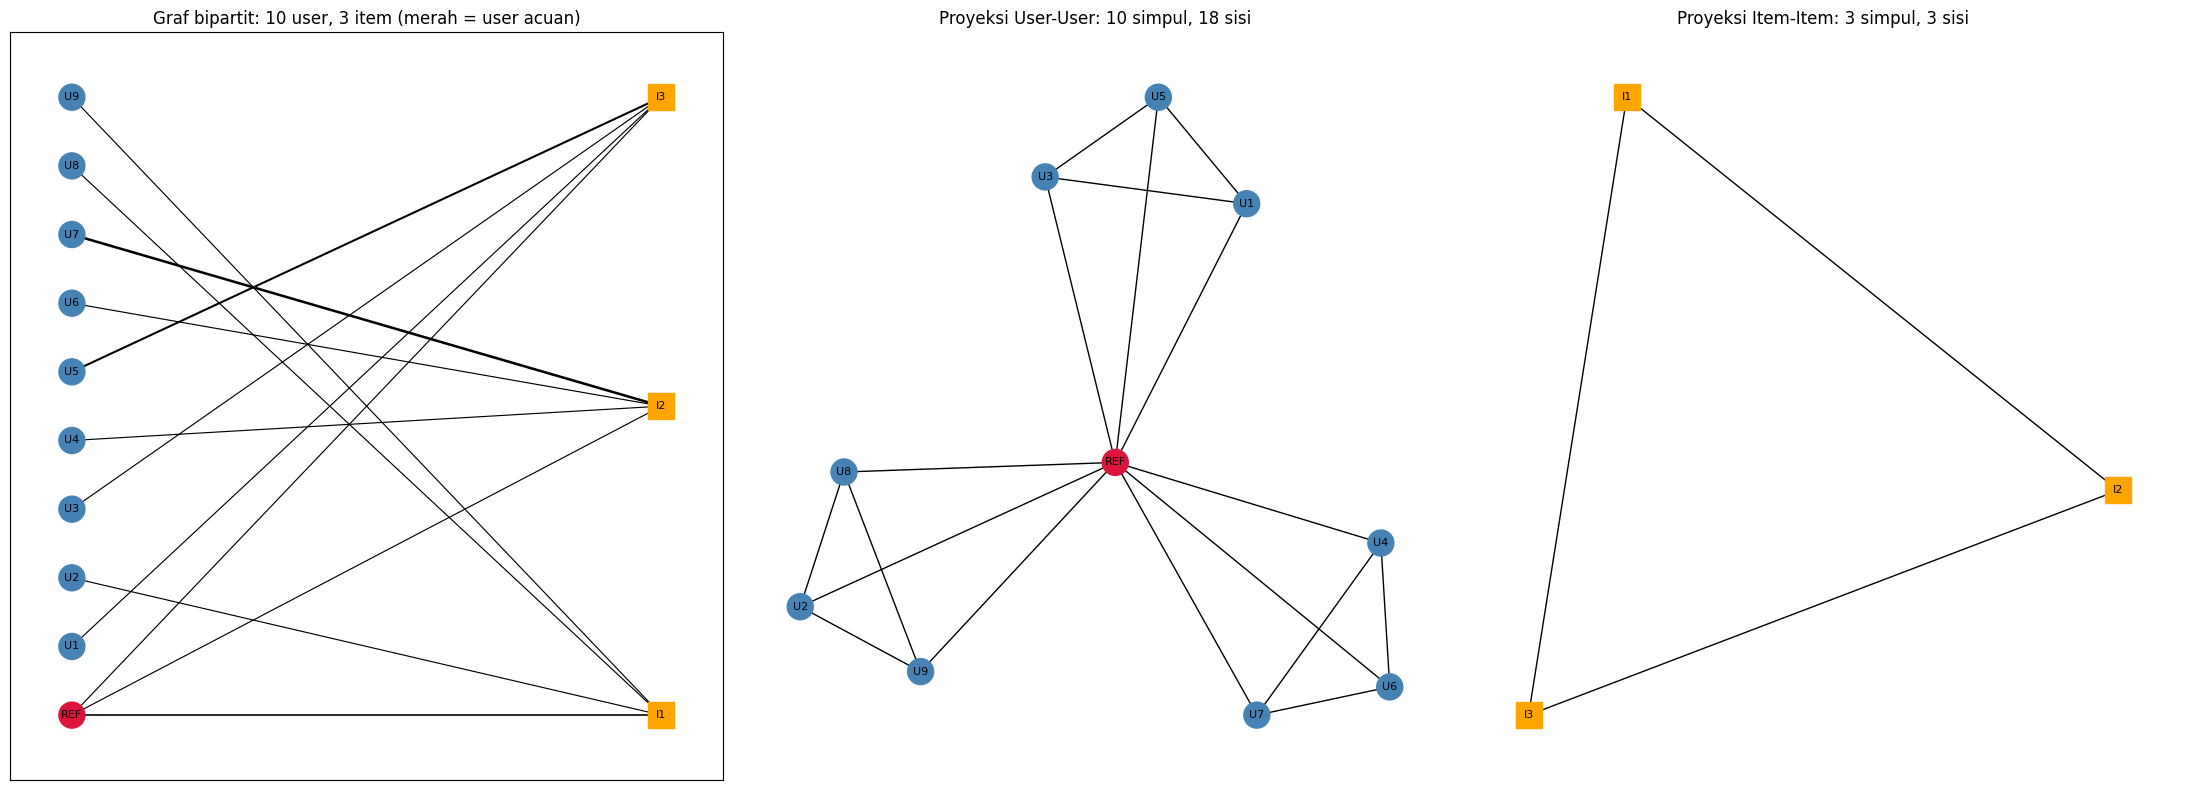

In [13]:
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite

deg_u = pairs.groupby("visitorid").size()
deg_i = pairs.groupby("itemid").size()
items_of = pairs.groupby("visitorid")["itemid"].apply(list)

# User acuan: 3-8 item dan item-nya populer, supaya graf contoh informatif (deterministik)
kandidat = [u for u in sorted(irisan) if 3 <= deg_u.get(u, 0) <= 8]
skor = {u: int(sum(deg_i[i] for i in items_of[u])) for u in kandidat}
ref = max(sorted(skor), key=skor.get)
print("REF = visitor", ref)

sub_ref = pairs[pairs.visitorid == ref]
others = (pairs[pairs.itemid.isin(sub_ref.itemid) & (pairs.visitorid != ref)]
          .sort_values(["itemid", "visitorid"]).groupby("itemid").head(3))
sub = pd.concat([sub_ref, others])

ulab = {u: ("REF" if u == ref else f"U{k}") for k, u in enumerate(sorted(sub.visitorid.unique()), 1)}
ilab = {i: f"I{k}" for k, i in enumerate(sorted(sub.itemid.unique()), 1)}

G = nx.Graph()
for u, i, w in sub.itertuples(index=False):
    G.add_node(ulab[u], bipartite=0)
    G.add_node(ilab[i], bipartite=1)
    G.add_edge(ulab[u], ilab[i], weight=w)

user_nodes = sorted(n for n, d in G.nodes(data=True) if d["bipartite"] == 0)
item_nodes = sorted(n for n, d in G.nodes(data=True) if d["bipartite"] == 1)
GU = bipartite.weighted_projected_graph(G, user_nodes)
GI = bipartite.weighted_projected_graph(G, item_nodes)

def warna(nodes):
    return ["crimson" if n == "REF" else "steelblue" for n in nodes]

fig, ax = plt.subplots(1, 3, figsize=(22, 8))
pos = nx.bipartite_layout(G, user_nodes)
nx.draw_networkx_nodes(G, pos, nodelist=user_nodes, node_color=warna(user_nodes), node_size=350, ax=ax[0])
nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="orange", node_shape="s", node_size=350, ax=ax[0])
nx.draw_networkx_edges(G, pos, ax=ax[0], width=[0.5 + G[a][b]["weight"] / 3 for a, b in G.edges])
nx.draw_networkx_labels(G, pos, font_size=8, ax=ax[0])
ax[0].set_title(f"Graf bipartit: {len(user_nodes)} user, {len(item_nodes)} item (merah = user acuan)")

nx.draw(GU, nx.spring_layout(GU, seed=42), ax=ax[1], node_color=warna(GU.nodes),
        node_size=350, with_labels=True, font_size=8)
ax[1].set_title(f"Proyeksi User-User: {GU.number_of_nodes()} simpul, {GU.number_of_edges()} sisi")

nx.draw(GI, nx.spring_layout(GI, seed=42), ax=ax[2], node_color="orange", node_shape="s",
        node_size=350, with_labels=True, font_size=8)
ax[2].set_title(f"Proyeksi Item-Item: {GI.number_of_nodes()} simpul, {GI.number_of_edges()} sisi")
plt.tight_layout()
plt.show()

**Cara membaca plot.**

- Kiri, graf bipartit: user (lingkaran biru, merah = user acuan) di sisi kiri dan item (kotak oranye) di sisi kanan. Garis yang lebih tebal berarti bobot interaksi lebih besar.
- Tengah, proyeksi User–User: dua user terhubung bila menyentuh item yang sama (10 simpul, 18 sisi).
- Kanan, proyeksi Item–Item: dua item terhubung bila disentuh oleh user yang sama (3 simpul, 3 sisi; ketiga item saling terhubung karena ada user, di antaranya user acuan, yang menyentuh ketiganya).

Contoh ini kecil, jadi hanya ilustrasi struktur. Perbandingan yang sebenarnya pada seluruh data dilakukan di no. 6.

## No. 6: Proyeksi mana yang lebih baik?

Kedua proyeksi dibandingkan dari sisi efisiensi (ukuran graf dan matriks similarity) dan efektivitas (seberapa kaya informasi vektornya). Sel berikut menghitung batas atas jumlah sisi dengan rumus kombinatorial, tanpa membentuk proyeksi penuh:

- Proyeksi User–User: tiap item yang disentuh d user menyumbang d(d−1)/2 pasangan user.
- Proyeksi Item–Item: tiap user yang menyentuh d item menyumbang d(d−1)/2 pasangan item.

Disebut batas atas karena dua simpul yang berbagi beberapa tetangga dihitung berkali-kali.

In [14]:
B = X.copy()
B.data[:] = 1                                   # biner: ada/tidak ada interaksi
deg_user = np.asarray(B.sum(axis=1)).ravel()    # jumlah item per user
deg_item = np.asarray(B.sum(axis=0)).ravel()    # jumlah user per item

sisi_user_user = int((deg_item * (deg_item - 1) / 2).sum())   # batas atas sisi User-User
sisi_item_item = int((deg_user * (deg_user - 1) / 2).sum())   # batas atas sisi Item-Item

n_u, n_i = X.shape
hasil = pd.DataFrame({
    "Proyeksi User-User": {"simpul": n_u, "batas atas sisi": sisi_user_user,
                           "matriks similarity dense (GB)": round(n_u**2 * 8 / 1e9, 1)},
    "Proyeksi Item-Item": {"simpul": n_i, "batas atas sisi": sisi_item_item,
                           "matriks similarity dense (GB)": round(n_i**2 * 8 / 1e9, 1)},
})
print(hasil)
print("Item terpopuler dilihat oleh", int(deg_item.max()), "user | user teraktif menyentuh", int(deg_user.max()), "item")

                               Proyeksi User-User  Proyeksi Item-Item
simpul                                   159344.0             78812.0
batas atas sisi                         1549414.0           1405463.0
matriks similarity dense (GB)               203.1                49.7
Item terpopuler dilihat oleh 334 user | user teraktif menyentuh 729 item


| | Proyeksi User–User | Proyeksi Item–Item |
|---|---|---|
| Simpul | 159.344 | **78.812** |
| Batas atas sisi | 1.549.414 | **1.405.463** |
| Matriks similarity dense | 203,1 GB | **49,7 GB** |

### Jawaban: proyeksi **Item–Item** lebih baik

1. **Efisiensi.** Simpulnya separuh (78.812 vs 159.344), batas atas sisinya sekitar 9% lebih sedikit, dan matriks similarity dense 4 kali lebih kecil. Karena kita memakai matriks sparse, keunggulan memori praktisnya lebih kecil daripada angka dense; yang paling nyata adalah jumlah simpul yang separuhnya.
2. **Efektivitas.** Vektor item lebih kaya informasi: rata-rata 2,94 elemen terisi dibanding 1,46 pada vektor user, dan hanya 55,4% item yang bervektor 1 elemen dibanding 81,6% pada user. Karena mayoritas user hanya menyentuh satu item, dua user yang menyentuh item yang sama langsung memiliki cosine 1 sehingga hampir tidak membedakan; item lebih dibedakan oleh himpunan user yang menyentuhnya.
3. **Rasio jumlah.** User (159.344) lebih banyak daripada item (78.812). Pendekatan item-based umumnya lebih stabil bila user jauh lebih banyak daripada item (heuristik umum yang tidak diuji di sini).

**Keterbatasan.** User teraktif menyentuh 729 item, yang menyumbang 265.356 pasangan (sekitar 18,9% dari batas atas) pada proyeksi Item–Item, sehingga proyeksi ini sensitif terhadap user yang sangat aktif. Batas atas ini juga bukan jumlah sisi sebenarnya; jumlah sebenarnya dihitung di no. 7 (1.347.962 pasangan item unik).

## No. 7: Similarity pada proyeksi Item–Item (Python)

Berdasarkan no. 6, similarity dihitung antar item. Metrik: cosine similarity pada vektor item berbobot (baris `Xi`):

cos(a, b) = (a · b) / (‖a‖ · ‖b‖)

Cosine mengukur kemiripan arah vektor, bukan panjangnya, sehingga item populer tidak otomatis menang. Karena semua elemen bernilai non-negatif, nilainya berada di antara 0 dan 1.

Implementasi: setiap baris dinormalisasi (L2), lalu dikalikan sebagai matriks sparse `Xi_n @ Xi_n.T`. Diagonal (item dengan dirinya sendiri) dibuang. Hanya pasangan item yang berbagi minimal satu user yang bernilai lebih dari 0. (Teks "Sel 13" pada output merujuk ke sel perhitungan batas atas di no. 6.)

In [15]:
from sklearn.preprocessing import normalize

Xi_n = normalize(Xi, norm="l2", axis=1)        # tiap vektor item dibuat panjang 1
S = (Xi_n @ Xi_n.T).tocsr()                     # cosine similarity item-item
S.setdiag(0); S.eliminate_zeros()               # buang similarity item dengan dirinya sendiri
S.data = np.clip(S.data, 0, 1)                  # buang error pembulatan (mis. 1.0000000002)

pasangan = S.nnz // 2
print("Shape S:", S.shape)
print("Pasangan item unik dengan similarity > 0:", pasangan)
print("Batas atas dari Sel 13:", sisi_item_item, "->", "OK" if pasangan <= sisi_item_item else "ADA YANG SALAH")

Shape S: (78812, 78812)
Pasangan item unik dengan similarity > 0: 1347962
Batas atas dari Sel 13: 1405463 -> OK


Hasilnya 1.347.962 pasangan item unik dengan similarity lebih dari 0. Jumlah ini tidak melebihi batas atas 1.405.463 (sekitar 95,9% darinya; selisihnya karena batas atas menghitung berulang pasangan yang berbagi beberapa user), dan hanya sekitar 0,043% dari seluruh kemungkinan pasangan item (3,1 miliar), sehingga matriks similarity sangat sparse.

Berikutnya, sebaran nilai similarity dan jumlah user yang dimiliki bersama tiap pasangan (`shared_users`), yang dipakai sebagai pembeda bila nilai similarity sama.

In [16]:
B_i = (Xi > 0).astype(np.float32)
C = (B_i @ B_i.T).tocsr()                       # jumlah user bersama tiap pasangan item
C.setdiag(0); C.eliminate_zeros()

U = sparse.triu(S, k=1).tocoo()
pairs_sim = pd.DataFrame({"item_a": item_ids[U.row], "item_b": item_ids[U.col], "similarity": U.data})
pairs_sim["shared_users"] = np.asarray(C[U.row, U.col]).ravel().astype(int)

print(pairs_sim["similarity"].describe())
print("Pasangan dengan similarity = 1.0:", int((pairs_sim.similarity >= 1 - 1e-9).sum()))

count    1.347962e+06
mean     2.006906e-01
std      2.494241e-01
min      2.200733e-04
25%      3.326845e-02
50%      9.128709e-02
75%      2.649065e-01
max      1.000000e+00
Name: similarity, dtype: float64
Pasangan dengan similarity = 1.0: 38081


Sebaran nilai miring ke kanan: median 0,091 lebih kecil daripada rata-rata 0,201, 75% pasangan bernilai di bawah 0,265, dan maksimumnya 1,0. Sebanyak 38.081 pasangan (2,8%) bernilai tepat 1,0. Nilai 1,0 muncul bila kedua vektor item searah, misalnya dua item yang hanya disentuh oleh satu user yang sama. Bukti seperti itu lemah (hanya 1–2 user bersama), sehingga saat similarity sama, urutan tetangga memakai `shared_users` (lalu `itemId`) sebagai pembeda.

Item acuan (record acuan yang ditentukan sendiri, secara deterministik): item dengan user terbanyak, lalu diambil 5 tetangga dengan similarity tertinggi (urut similarity turun, `shared_users` turun, `itemId` naik).

In [17]:
deg_item_s = pd.Series(deg_item, index=item_ids)
ref_item = int(deg_item_s.idxmax())             # item acuan: paling banyak dikunjungi user (deterministik)
r = np.searchsorted(item_ids, ref_item)

row = S.getrow(r).tocoo()                       # similarity item acuan ke semua item lain
c_row = C.getrow(r).toarray().ravel()           # jumlah user bersama, diubah ke array biasa

top = pd.DataFrame({"item_acuan": ref_item,
                    "item_tetangga": item_ids[row.col],
                    "similarity": row.data})
top["shared_users"] = c_row[row.col].astype(int)
assert (top["shared_users"] > 0).all()          # similarity > 0 pasti berarti ada user bersama

top = (top.sort_values(["similarity", "shared_users", "item_tetangga"], ascending=[False, False, True])
          .head(5).reset_index(drop=True))
print("Item acuan:", ref_item, "| jumlah tetangga:", row.nnz)
top

Item acuan: 370653 | jumlah tetangga: 237


,item_acuan,item_tetangga,similarity,shared_users
0,370653,10132,0.123728,7
1,370653,84160,0.114867,30
2,370653,335975,0.088370,21
3,370653,378621,0.076948,4
4,370653,91755,0.058759,16


Item acuan 370653 (item terpopuler di P1, disentuh 334 user) memiliki 237 tetangga. Lima tetangga teratasnya: 10132 (0,1237), 84160 (0,1149), 335975 (0,0884), 378621 (0,0769), dan 91755 (0,0588). Nilainya relatif kecil (0,06–0,12) karena vektor item acuan melibatkan 334 user, sedangkan tiap tetangga hanya beririsan dengan sebagian kecil dari mereka (4–30 user bersama).

## No. 7a: Cypher untuk 5 record dengan similarity tertinggi

Record acuan: item 370653. Cypher berikut menghitung cosine langsung di Neo4j pada vektor item berbobot yang sama (view 1, addtocart 3, transaction 5), lalu hasilnya dibandingkan dengan hasil Python. Cara kerjanya (tiap `WITH` meneruskan hasil ke tahap berikutnya):

1. `MATCH (v:Visitor)-[r]->(a:Item {itemId: $ref})` dengan `sum(CASE type(r) ...)` menghasilkan bobot `wa` tiap visitor terhadap item acuan. `collect(...)` dan `sqrt(sum(wa * wa))` menghasilkan daftar visitor beserta norma ‖a‖.
2. `UNWIND` lalu `MATCH (v)-[r2]->(b:Item) WHERE b <> a` mencari item lain yang disentuh visitor yang sama beserta bobotnya `wb`. `sum(wa * wb)` per item b adalah hasil kali dalam (a · b), dan `count(v)` adalah `shared_users`.
3. `MATCH (u:Visitor)-[r3]->(b)` mengambil **semua** user yang menyentuh b (termasuk yang tidak menyentuh item acuan) untuk menghitung norma ‖b‖ = √Σ wbu².
4. `dot / (na * nb)` adalah cosine. `ORDER BY similarity DESC, shared_users DESC, item_tetangga ASC LIMIT 5` mengambil lima teratas.

**Urutan pengerjaan:** 7a, lalu no. 8 (kondisi sebelum), lalu 7b, lalu no. 8 (kondisi sesudah), karena kondisi "sebelum" harus diambil sebelum relasi `SIMILAR_TO` ditulis.

In [18]:
CYPHER_TOP5 = """
MATCH (v:Visitor)-[r]->(a:Item {itemId: $ref})
WITH a, v, sum(CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS wa
WITH a, collect({v: v, wa: wa}) AS ua, sqrt(sum(wa * wa)) AS na
UNWIND ua AS x
WITH a, na, x.v AS v, x.wa AS wa
MATCH (v)-[r2]->(b:Item) WHERE b <> a
WITH a, na, b, v, wa,
     sum(CASE type(r2) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS wb
WITH a, na, b, sum(wa * wb) AS dot, count(v) AS shared
MATCH (u:Visitor)-[r3]->(b)
WITH a, na, b, dot, shared, u,
     sum(CASE type(r3) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS wbu
WITH a, na, b, dot, shared, sqrt(sum(wbu * wbu)) AS nb
RETURN a.itemId AS item_acuan, b.itemId AS item_tetangga,
       dot / (na * nb) AS similarity, shared AS shared_users
ORDER BY similarity DESC, shared_users DESC, item_tetangga ASC
LIMIT 5
"""

records, _, _ = driver.execute_query(CYPHER_TOP5, ref=ref_item,
                                     database_=DATABASE, routing_=RoutingControl.READ)
top_cy = pd.DataFrame([r.data() for r in records])
print(top_cy)

cocok = (top_cy.item_tetangga.tolist() == top.item_tetangga.tolist()
         and top_cy.shared_users.tolist() == top.shared_users.tolist()
         and np.allclose(top_cy.similarity, top.similarity, atol=1e-9))
print("Cocok dengan hasil Python:", cocok)

   item_acuan  item_tetangga  similarity  shared_users
0      370653          10132    0.123728             7
1      370653          84160    0.114867            30
2      370653         335975    0.088370            21
3      370653         378621    0.076948             4
4      370653          91755    0.058759            16
Cocok dengan hasil Python: True


Hasil Cypher sama dengan hasil Python (`Cocok dengan hasil Python: True`; nilai dibandingkan dengan `np.allclose`, dan keenam digit desimal yang ditampilkan identik). Dua jalur perhitungan yang independen menghasilkan lima tetangga, urutan, dan nilai yang sama.

## No. 8: Kondisi sebelum dan sesudah perhitungan similarity

### Sebelum (belum ada relasi `SIMILAR_TO`)

Cypher yang dipakai:

- Jumlah relasi per jenis: `MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY relasi`
- Subgraf contoh, yaitu visitor yang menyentuh item acuan dan salah satu dari lima tetangganya, beserta item yang ia sentuh:
  `MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item) WHERE b.itemId IN $nei RETURN DISTINCT v.visitorId AS visitor, b.itemId AS item`

In [19]:
NEI = [int(x) for x in top.item_tetangga]

Q_SUB = """
MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
      -[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b.itemId IN $nei
RETURN DISTINCT v.visitorId AS visitor, b.itemId AS item
"""
Q_COUNT = "MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY relasi"

def ambil_subgraf():
    recs, _, _ = driver.execute_query(Q_SUB, ref=ref_item, nei=NEI,
                                      database_=DATABASE, routing_=RoutingControl.READ)
    return pd.DataFrame([r.data() for r in recs])

sebelum = run_query(Q_COUNT)
sub_before = ambil_subgraf()
print(sebelum)
print("Visitor yang menyentuh item acuan DAN salah satu tetangga:", sub_before.visitor.nunique())

          relasi  jumlah
0  ADDED_TO_CART    6939
1         BOUGHT    2207
2         VIEWED  285187
Visitor yang menyentuh item acuan DAN salah satu tetangga: 65


Sebelum perhitungan similarity hanya ada tiga jenis relasi (VIEWED 285.187; ADDED_TO_CART 6.939; BOUGHT 2.207) dan tidak ada `SIMILAR_TO`. Ada 65 visitor yang menyentuh item acuan dan minimal satu tetangganya; merekalah yang membentuk subgraf contoh pada plot.

## No. 7b: Menuliskan similarity ke graf

Kelima nilai tertinggi ditulis sebagai relasi `(:Item)-[:SIMILAR_TO {score, shared_users, metric, period}]->(:Item)` dari item acuan ke tiap tetangga:

- `MATCH` menemukan dua item,
- `MERGE` membuat relasi bila belum ada (idempoten: bila dijalankan ulang tidak menggandakan relasi),
- `SET` mengisi properti: `score` (cosine), `shared_users`, `metric = 'cosine'`, dan `period = 'P1'`.

Hanya lima relasi yang ditulis (bukan 1,35 juta pasangan), sesuai soal yang meminta "similarity-similarity tersebut" (lima record teratas), dan agar graf tetap ringan.

In [20]:
Q_WRITE = """
UNWIND $rows AS row
MATCH (a:Item {itemId: row.a}), (b:Item {itemId: row.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.shared_users = row.shared, s.metric = 'cosine', s.period = 'P1'
"""
rows = [{"a": int(r.item_acuan), "b": int(r.item_tetangga),
         "score": float(r.similarity), "shared": int(r.shared_users)} for r in top.itertuples()]
driver.execute_query(Q_WRITE, rows=rows, database_=DATABASE)

Q_READ = """
MATCH (a:Item)-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_tetangga,
       s.score AS similarity, s.shared_users AS shared_users
ORDER BY similarity DESC, shared_users DESC, item_tetangga
"""
run_query(Q_READ)

,item_acuan,item_tetangga,similarity,shared_users
0,370653,10132,0.123728,7
1,370653,84160,0.114867,30
2,370653,335975,0.088370,21
3,370653,378621,0.076948,4
4,370653,91755,0.058759,16


Query `MATCH (a:Item)-[s:SIMILAR_TO]->(b:Item) RETURN ... ORDER BY similarity DESC ...` menampilkan lima relasi yang kini tersimpan di graf. Nilainya identik dengan hasil Python dan Cypher pada 7a.

### Sesudah (relasi `SIMILAR_TO` sudah ditulis)

Cypher untuk jumlah relasi per jenis sama dengan kondisi sebelum (`Q_COUNT`), lalu graf subgraf yang sama digambar dua kali: tanpa dan dengan relasi `SIMILAR_TO`.

          relasi  jumlah
0  ADDED_TO_CART    6939
1         BOUGHT    2207
2     SIMILAR_TO       5
3         VIEWED  285187


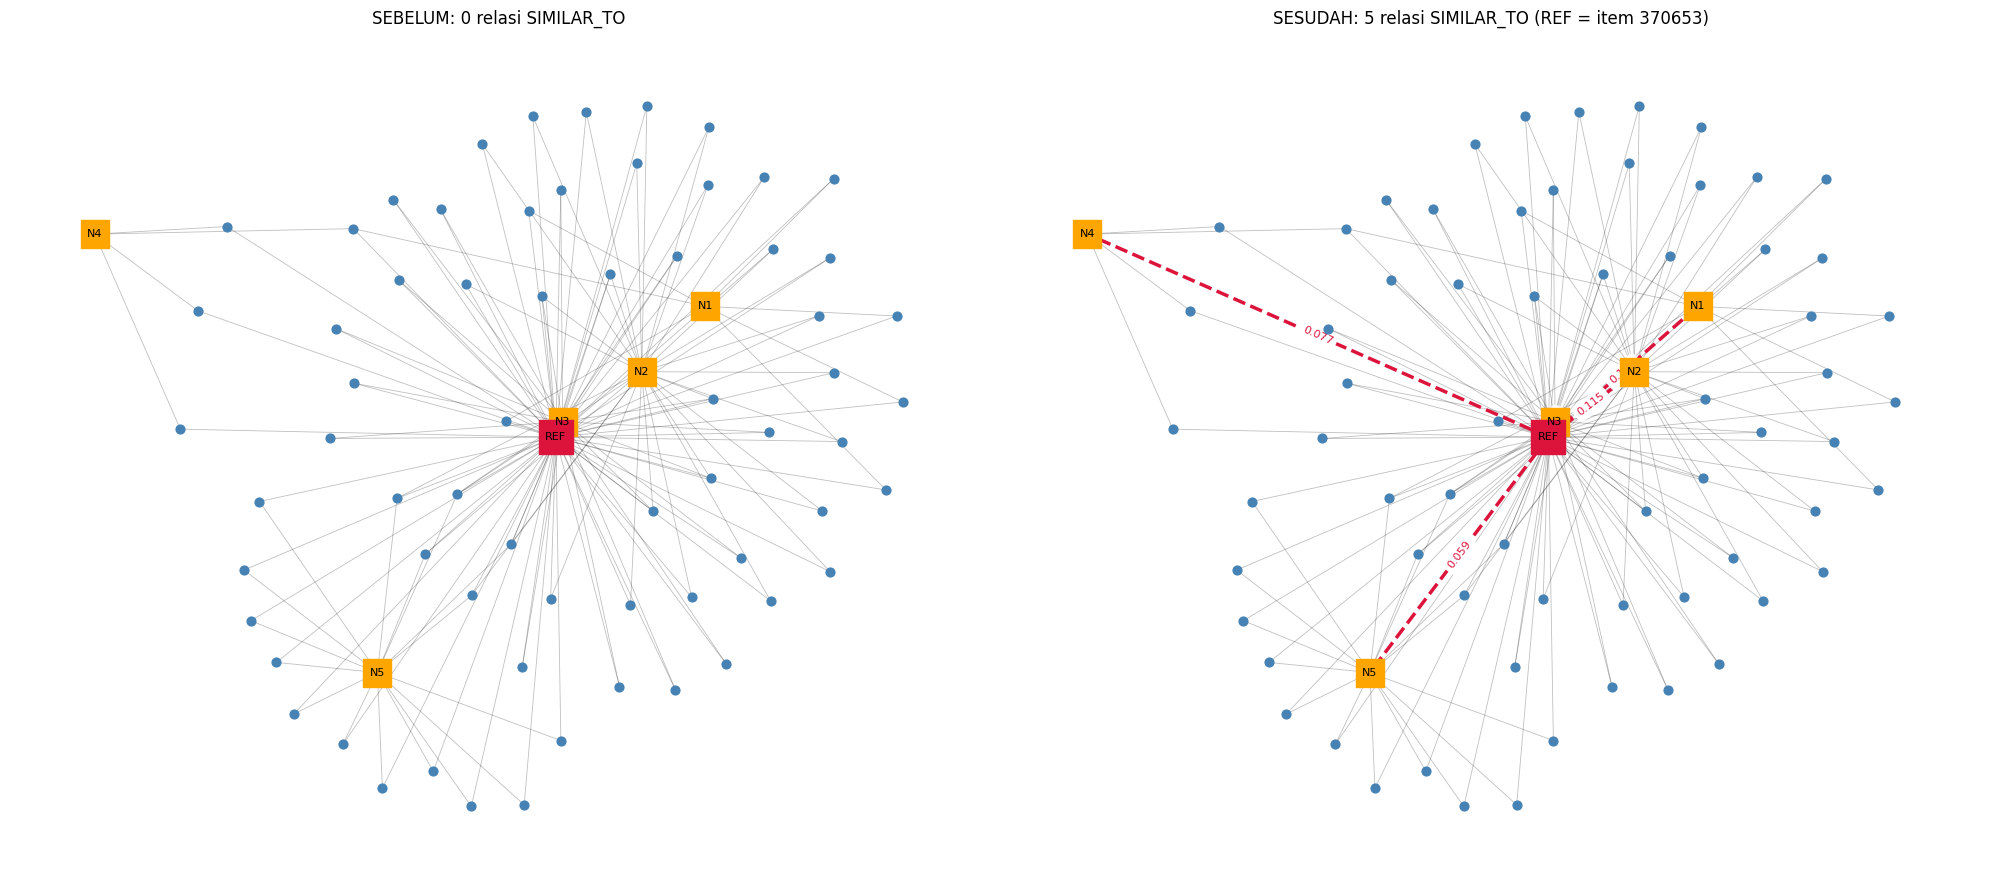

In [21]:
sesudah = run_query(Q_COUNT)
print(sesudah)

lab = {ref_item: "REF"}
lab.update({int(b): f"N{k}" for k, b in enumerate(top.item_tetangga, 1)})

G0 = nx.Graph()
for v, b in sub_before.itertuples(index=False):
    G0.add_edge(f"v{v}", "REF")
    G0.add_edge(f"v{v}", lab[b])
pos = nx.spring_layout(G0, seed=42, k=0.4)

G1 = G0.copy()
for r in top.itertuples():
    G1.add_edge("REF", lab[int(r.item_tetangga)], score=float(r.similarity))

def gambar(ax, G, judul):
    vis = [n for n in G if n.startswith("v")]
    nei = [n for n in G if n.startswith("N")]
    base = [(a, b) for a, b, d in G.edges(data=True) if "score" not in d]
    sim = [(a, b) for a, b, d in G.edges(data=True) if "score" in d]
    nx.draw_networkx_edges(G, pos, edgelist=base, alpha=0.25, width=0.6, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=vis, node_color="steelblue", node_size=40, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=nei, node_color="orange", node_shape="s", node_size=380, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=["REF"], node_color="crimson", node_shape="s", node_size=600, ax=ax)
    nx.draw_networkx_labels(G, pos, labels={n: n for n in ["REF"] + nei}, font_size=8, ax=ax)
    if sim:
        nx.draw_networkx_edges(G, pos, edgelist=sim, edge_color="crimson", width=2.5, style="dashed", ax=ax)
        nx.draw_networkx_edge_labels(G, pos, edge_labels={(a, b): f"{G[a][b]['score']:.3f}" for a, b in sim},
                                     font_size=8, font_color="crimson", ax=ax)
    ax.set_title(judul)
    ax.axis("off")

fig, ax = plt.subplots(1, 2, figsize=(20, 9))
gambar(ax[0], G0, "SEBELUM: 0 relasi SIMILAR_TO")
gambar(ax[1], G1, "SESUDAH: 5 relasi SIMILAR_TO (REF = item 370653)")
plt.tight_layout()
plt.show()

Sesudah perhitungan similarity, relasi `SIMILAR_TO` berjumlah 5 dan jumlah relasi lain tidak berubah (total 294.338 relasi).

**Membaca plot:** titik biru adalah visitor, kotak merah adalah item acuan 370653, kotak oranye adalah lima tetangga (N1 = 10132, N2 = 84160, N3 = 335975, N4 = 378621, N5 = 91755), dan garis merah putus-putus adalah relasi `SIMILAR_TO` beserta nilainya. Plot kiri dan kanan memakai tata letak yang sama (seed 42), sehingga satu-satunya perbedaan adalah lima garis merah. Catatan: N2 (0,115) letaknya berimpit dengan item acuan sehingga labelnya tertutup; nilainya ada di tabel pada 7b.

### Tampilan graf di Neo4j Query

Query berikut dijalankan langsung di Neo4j Query (bukan lewat Python). Kondisi sebelum diambil dengan menghapus sementara kelima relasi `SIMILAR_TO` (`MATCH ()-[s:SIMILAR_TO]->() DELETE s`), lalu relasi tersebut dikembalikan sehingga kondisi akhir graf kembali berisi 5 relasi `SIMILAR_TO`.

#### Sebelum (belum ada relasi `SIMILAR_TO`)

**1. Jumlah relasi `SIMILAR_TO`:**

```cypher
MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_similar_to
```

Hasilnya **0**.

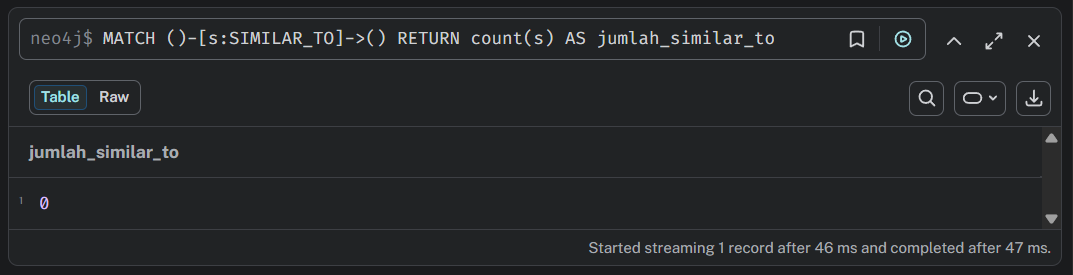

**2. Subgraf: visitor yang menyentuh item acuan dan kelima tetangganya:**

```cypher
MATCH (a:Item {itemId: 370653})<-[r1]-(v:Visitor)-[r2]->(b:Item)
WHERE b.itemId IN [10132, 84160, 335975, 378621, 91755]
RETURN a, r1, v, r2, b LIMIT 150
```

Panel *Database information* menunjukkan Relationships (294,333) = 285.187 + 6.939 + 2.207, tanpa label `SIMILAR_TO`; graf berisi 113 record. (Daftar *Property keys* masih memuat `score`, `shared_users`, `metric`, dan `period` karena nama properti tetap tercatat di katalog database walaupun relasinya sudah dihapus.)

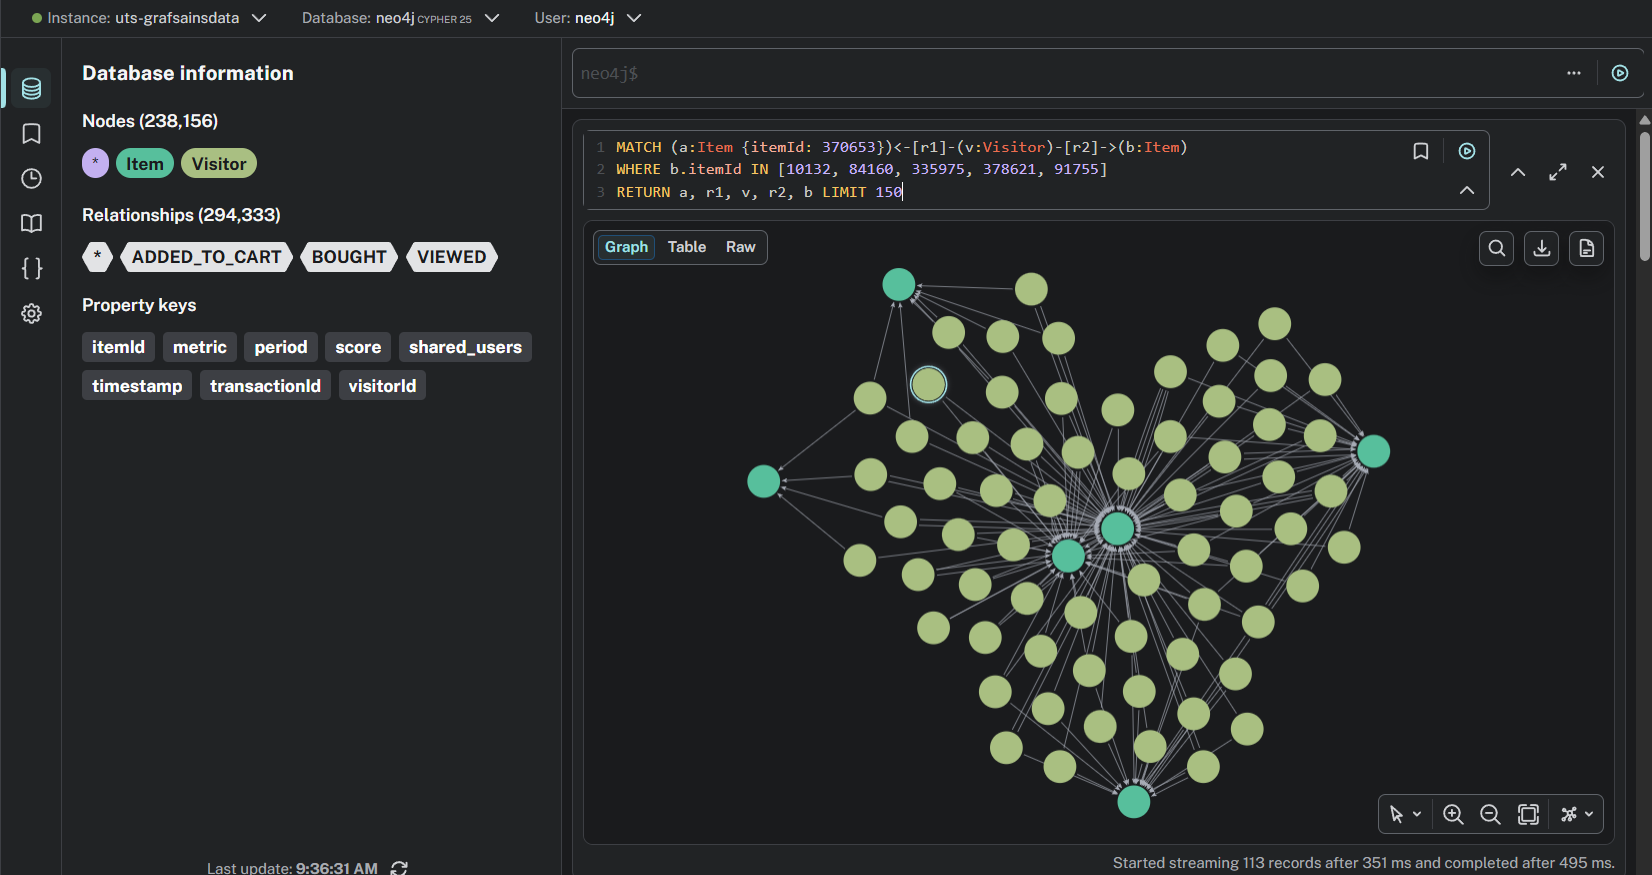

#### Sesudah (relasi `SIMILAR_TO` sudah ditulis)

**3. Jumlah relasi `SIMILAR_TO` dan ringkasan database:**

```cypher
MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_similar_to
```

Hasilnya **5**; panel *Database information* menunjukkan 238.156 simpul dan 294.338 relasi (285.187 + 6.939 + 2.207 + 5), dan label `SIMILAR_TO` kini muncul.

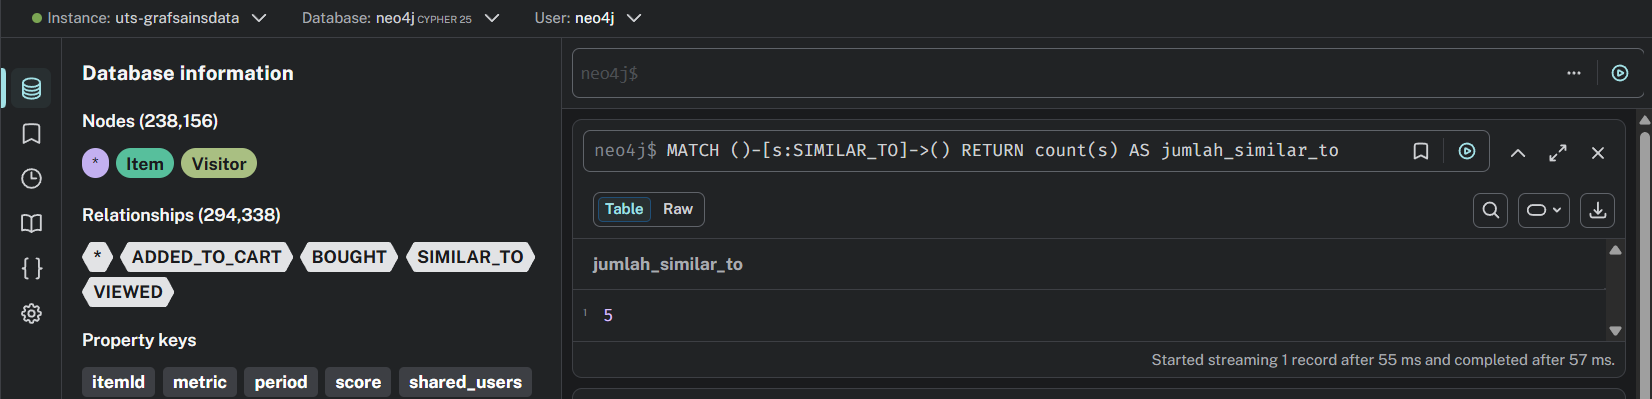

**4. Relasi `SIMILAR_TO` dari item acuan ke lima tetangga:**

```cypher
MATCH p = (a:Item {itemId: 370653})-[:SIMILAR_TO]->(b:Item) RETURN p
```

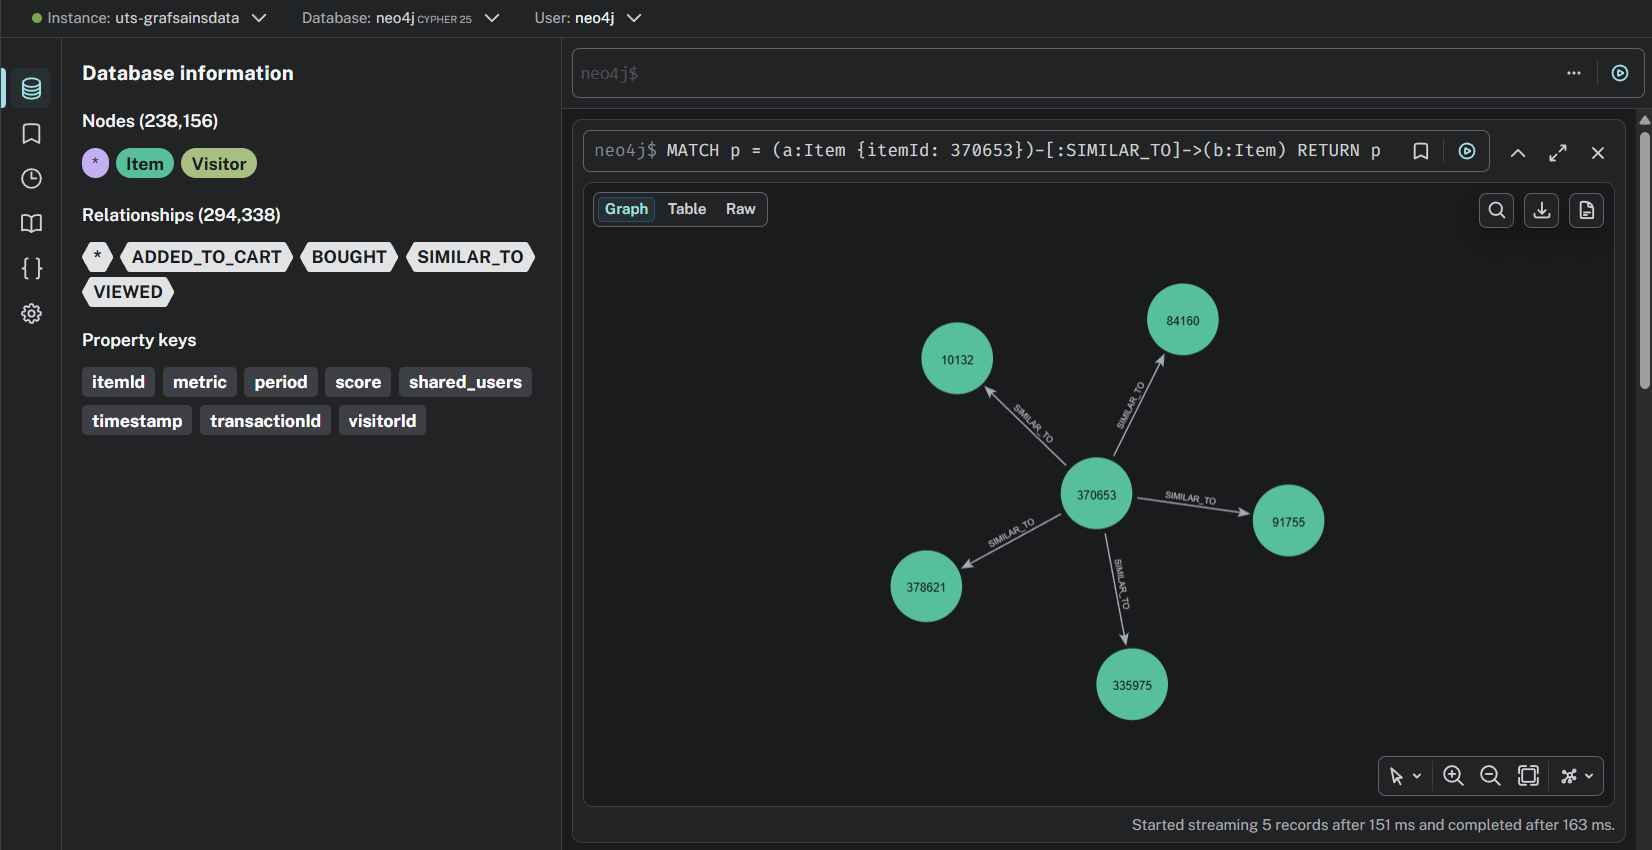

**5. Gabungan: relasi `SIMILAR_TO` bersama visitor yang menyentuh kedua item:**

```cypher
MATCH (a:Item {itemId: 370653})-[s:SIMILAR_TO]->(b:Item)
OPTIONAL MATCH (a)<-[r1]-(v:Visitor)-[r2]->(b)
RETURN a, s, b, r1, v, r2 LIMIT 150
```

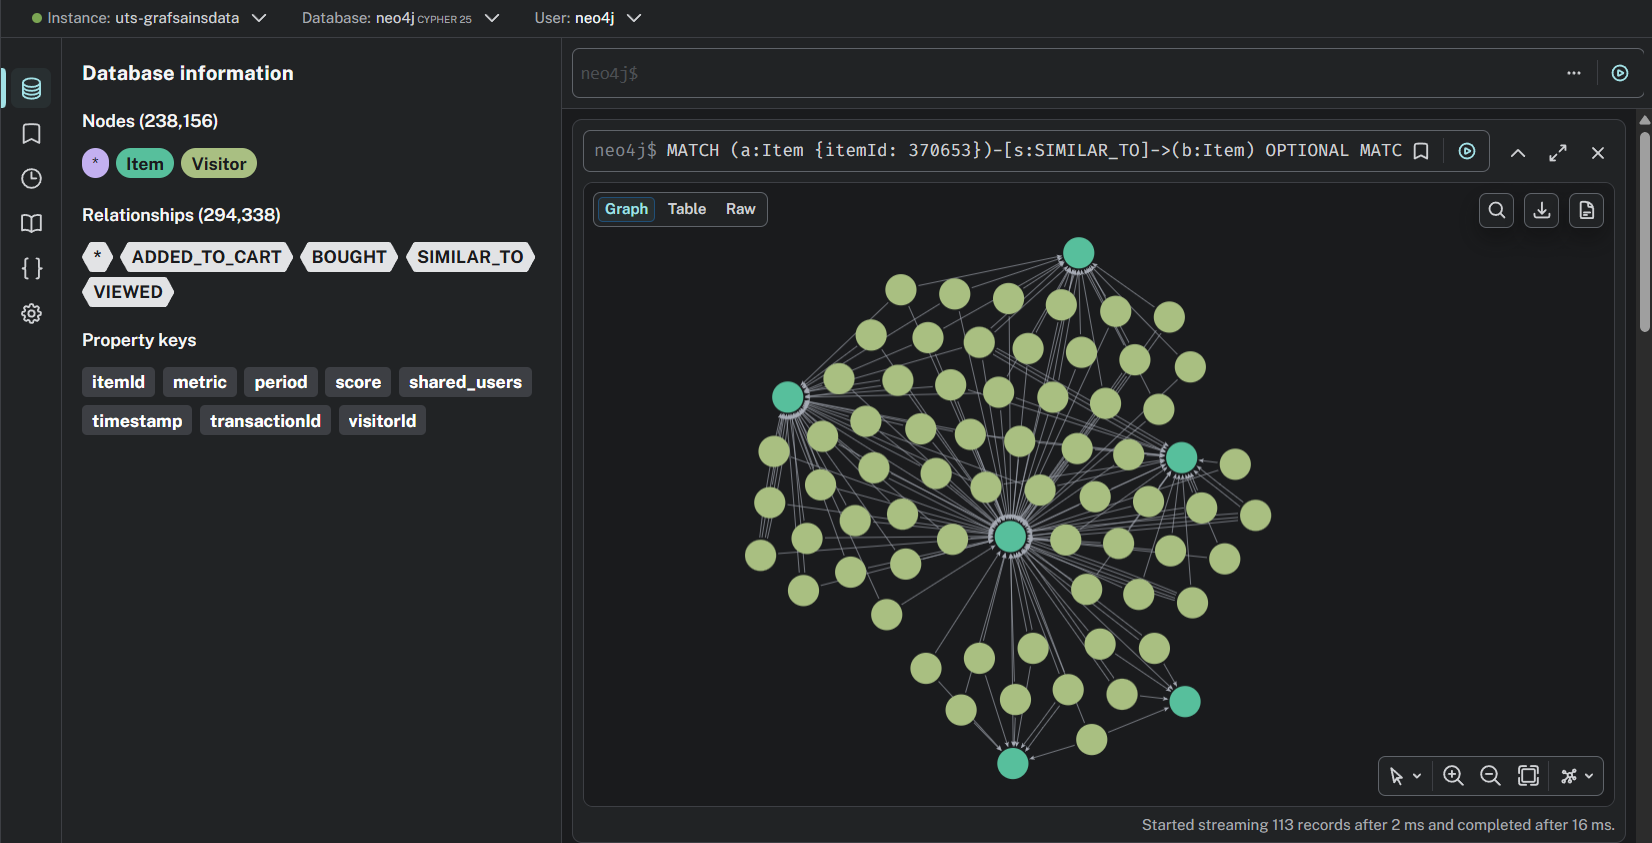

## 2.2 Analytics

### Rancangan

- **Model:** KNN item-based dengan k = 5, konsisten dengan proyeksi Item–Item (no. 6) dan cosine similarity (no. 7).
- **Data:** rekomendasi dibangun hanya dari P1 (matriks `X` dan similarity `S`). P2 hanya dipakai untuk evaluasi.
- **Ground truth:** item yang disentuh user di P2 (view, addtocart, atau transaction) yang belum pernah disentuhnya di P1, karena item yang sudah dikenal tidak direkomendasikan.
- **Pemilihan user acak yang dapat direproduksi:** `numpy.random.default_rng(42)` memilih satu user dari daftar user yang layak dievaluasi (diurutkan naik berdasarkan ID). User layak bila ada di P1 dan P2, ground truth-nya tidak kosong, dan sistem menghasilkan minimal 5 kandidat. Kriteria ini murni teknis (agar Hit@5 dan NDCG@5 dapat dihitung) dan ditetapkan sebelum melihat hasil.

### No. 1a: Skrip KNN

Fungsi `recommend(u_row)` bekerja dalam empat langkah:

1. Ambil item P1 milik user beserta bobotnya (w).
2. Untuk tiap item, ambil k = 5 tetangga terdekat dari matriks similarity `S` (similarity turun; bila seri, `itemId` naik).
3. Buang item yang sudah ada di riwayat user.
4. Skor kandidat j = Σ (w(i) × similarity(i, j)) atas semua item sumber i. Kandidat diurutkan menurut skor turun (seri: `itemId` naik) dan diambil 5 teratas.

In [22]:
K, TOPN, N_ADS, SEED = 5, 5, 3, 42

p2_items = p2.groupby("visitorid")["itemid"].apply(set)
rows_of = dict(zip(user_ids.tolist(), range(len(user_ids))))

def knn_items(item_idx, k=K):
    """k tetangga terdekat satu item: similarity turun, lalu itemId naik."""
    r = S.getrow(item_idx).tocoo()
    order = np.lexsort((r.col, -r.data))[:k]
    return r.col[order], r.data[order]

def recommend(u_row, k=K, topn=TOPN):
    s, e = X.indptr[u_row], X.indptr[u_row + 1]
    seen_idx, seen_w = X.indices[s:e], X.data[s:e]     # item P1 user beserta bobotnya
    seen = set(seen_idx.tolist())
    skor, asal = {}, {}
    for i, w in zip(seen_idx, seen_w):
        nb, sim = knn_items(i, k)
        for j, sm in zip(nb.tolist(), sim):
            if j in seen:
                continue                                # jangan rekomendasikan yang sudah dikenal
            skor[j] = skor.get(j, 0.0) + w * sm         # skor = jumlah (bobot user x similarity)
            asal.setdefault(j, []).append(int(item_ids[i]))
    if not skor:
        return pd.DataFrame(columns=["itemid", "skor", "berasal_dari"])
    rec = pd.DataFrame({"itemid": item_ids[list(skor)],
                        "skor": list(skor.values()),
                        "berasal_dari": [asal[j] for j in skor]})
    return (rec.sort_values(["skor", "itemid"], ascending=[False, True])
               .head(topn).reset_index(drop=True))

def truth_baru(visitor, u_row):
    s, e = X.indptr[u_row], X.indptr[u_row + 1]
    seen_items = set(item_ids[X.indices[s:e]].tolist())
    return p2_items[visitor] - seen_items

eligible = []
for v in sorted(irisan):
    u = rows_of[v]
    if len(truth_baru(v, u)) == 0:
        continue
    if len(recommend(u)) < TOPN:
        continue
    eligible.append(v)

print("User di P1 dan P2:", len(irisan), "| layak dievaluasi:", len(eligible))

rng = np.random.default_rng(SEED)
ref_user = int(rng.choice(eligible))
u_row = rows_of[ref_user]
print("User terpilih (seed =", SEED, "):", ref_user)

User di P1 dan P2: 2779 | layak dievaluasi: 1337
User terpilih (seed = 42 ): 121532


Dari 2.779 user yang ada di P1 dan P2, 1.337 user layak dievaluasi (1.442 lainnya tidak layak karena ground truth kosong atau kurang dari 5 kandidat). Dengan seed 42, user yang terpilih adalah visitor 121532.

### No. 1b: 3 item yang diiklankan (k = 5)

Riwayat user di P1, peringkat lima kandidat, dan tiga teratas sebagai item yang diiklankan.

In [23]:
hist = (edges[edges.visitorid == ref_user]
        .pivot_table(index="itemid", columns="tipe", values="n", aggfunc="sum", fill_value=0))
print("Riwayat user di P1:")
display(hist)

rec = recommend(u_row)
print("Peringkat 5 kandidat:")
display(rec)

ads = rec.head(N_ADS)
print("3 ITEM YANG DIIKLANKAN (k = 5):", ads.itemid.tolist())

Riwayat user di P1:


tipe,VIEWED
itemid,
21660,1
62346,1
68633,1
142905,1
171021,1
179033,1
195152,1


Peringkat 5 kandidat:


,itemid,skor,berasal_dari
0,12315,0.98387,[179033]
1,33645,0.98387,[179033]
2,39037,0.98387,[179033]
3,39948,0.98387,[179033]
4,50700,0.98387,[179033]


3 ITEM YANG DIIKLANKAN (k = 5): [12315, 33645, 39037]


**3 item yang diiklankan: 12315, 33645, 39037.**

Riwayat user di P1 terdiri atas 7 item, semuanya `VIEWED` satu kali. Kelima kandidat berasal dari satu item sumber saja (179033) dan memiliki skor yang sama persis (0,98387 = bobot 1 × similarity 0,98387). Karena itu urutan peringkatnya, termasuk pemilihan tiga item iklan, ditentukan oleh aturan seri `itemId` naik, bukan oleh perbedaan tingkat kemiripan. Tidak ada dasar untuk mengatakan 12315 lebih cocok daripada 39948.

### No. 2: Evaluasi Hit@5 dan NDCG@5

Relevansi bersifat biner: item bernilai 1 bila ada di ground truth, dan 0 bila tidak.

- **Hit@5** = 1 bila minimal satu dari 5 item teratas ada di ground truth, dan 0 bila tidak.
- **NDCG@5** = DCG@5 / IDCG@5, dengan DCG@5 = Σ rel(i) / log₂(i + 1) untuk posisi i = 1..5, dan IDCG@5 adalah DCG ideal (semua item relevan berada di posisi teratas) = Σ 1 / log₂(i + 1) untuk i = 1..min(|ground truth|, 5).

Daftar yang dievaluasi adalah 5 item peringkat teratas (tiga yang pertama adalah item iklan). Sebagai pelengkap, dicetak juga Hit@3 dan NDCG@3 untuk tiga item iklan saja, yaitu penafsiran paling ketat dari "berdasarkan hasil no. 1b".

In [24]:
def hit_at_k(rec_items, truth, k):
    return int(any(i in truth for i in list(rec_items)[:k]))

def ndcg_at_k(rec_items, truth, k):
    lst = list(rec_items)[:k]
    dcg = sum(1.0 / np.log2(pos + 2) for pos, i in enumerate(lst) if i in truth)
    idcg = sum(1.0 / np.log2(pos + 2) for pos in range(min(len(truth), k)))
    return dcg / idcg if idcg > 0 else 0.0

truth = truth_baru(ref_user, u_row)
rec_items = rec.itemid.tolist()

print("Aktivitas user di P2:", p2[p2.visitorid == ref_user].event.value_counts().to_dict())
print("Ground truth (item P2 yang belum ada di P1):", sorted(truth))
print("Item rekomendasi yang kena (hit):", [i for i in rec_items if i in truth])
print("---")
print("Hit@5  =", hit_at_k(rec_items, truth, 5))
print("NDCG@5 =", round(ndcg_at_k(rec_items, truth, 5), 4))
print("Pelengkap, hanya 3 item yang diiklankan: Hit@3 =", hit_at_k(rec_items, truth, 3),
      "| NDCG@3 =", round(ndcg_at_k(rec_items, truth, 3), 4))

Aktivitas user di P2: {'view': 2}
Ground truth (item P2 yang belum ada di P1): [300290, 397699]
Item rekomendasi yang kena (hit): []
---
Hit@5  = 0
NDCG@5 = 0.0
Pelengkap, hanya 3 item yang diiklankan: Hit@3 = 0 | NDCG@3 = 0.0


### No. 2a: Hit@5

Aktivitas visitor 121532 di P2 adalah 2 kali view, sehingga ground truth-nya {300290, 397699} (keduanya ada di P1, jadi secara prinsip dapat direkomendasikan). Tidak ada satu pun dari 12315, 33645, 39037, 39948, 50700 yang termasuk ground truth, sehingga Hit@5 = 0.

### No. 2b: NDCG@5

Ground truth berisi 2 item, sehingga IDCG@5 = 1/log₂(2) + 1/log₂(3) = 1 + 0,6309 = 1,6309. Seluruh rel(i) = 0, sehingga DCG@5 = 0 dan NDCG@5 = 0 / 1,6309 = 0.

Kalau hanya tiga item iklan yang dihitung, hasilnya sama: Hit@3 = 0 dan NDCG@3 = 0. Jadi perbedaan penafsiran soal tidak mengubah jawaban.

**Konteks: rata-rata pada semua user layak.** Sel berikut bukan jawaban soal, hanya untuk menilai apakah hasil nol pada satu user itu wajar.

In [25]:
hasil = []
for v in eligible:
    u = rows_of[v]
    t = truth_baru(v, u)
    r = recommend(u).itemid.tolist()
    hasil.append((v, hit_at_k(r, t, 5), ndcg_at_k(r, t, 5)))
res = pd.DataFrame(hasil, columns=["visitor", "hit5", "ndcg5"])
print("User dievaluasi:", len(res), "| Hit@5 rata-rata:", round(res.hit5.mean(), 4),
      "| NDCG@5 rata-rata:", round(res.ndcg5.mean(), 4))

User dievaluasi: 1337 | Hit@5 rata-rata: 0.0075 | NDCG@5 rata-rata: 0.0039


Pada 1.337 user layak, Hit@5 rata-rata hanya 0,0075 (sekitar 10 dari 1.337 user) dan NDCG@5 rata-rata 0,0039. Jadi hasil nol untuk user terpilih adalah hasil yang umum di data ini: hampir semua user mendapat nilai 0. Rendahnya nilai konsisten dengan riwayat user yang pendek (rata-rata 1,46 item per user), P1 yang hanya 14 hari, dan jeda lebih dari 6 minggu dari P1 ke P2.

### Diagnosis: mengapa hasilnya 0 untuk user terpilih?

Dua sel berikut mengecek (1) apakah item ground truth ada di P1 dan berapa banyak tetangga tiap item riwayat, serta (2) tetangga teratas tiap item riwayat beserta jumlah user yang menyentuhnya.

In [26]:
item_set = set(item_ids.tolist())
print("Ground truth ada di P1?", {i: (i in item_set) for i in truth})
print("Item riwayat user yang punya tetangga di S:",
      {int(item_ids[i]): int(S.getrow(i).nnz) for i in X.indices[X.indptr[u_row]:X.indptr[u_row + 1]]})

Ground truth ada di P1? {300290: True, 397699: True}
Item riwayat user yang punya tetangga di S: {21660: 6, 62346: 6, 68633: 6, 142905: 6, 171021: 6, 179033: 748, 195152: 17}


In [27]:
seen_idx = X.indices[X.indptr[u_row]:X.indptr[u_row + 1]]
seen_set = set(seen_idx.tolist())
for i in seen_idx:
    nb, sim = knn_items(i)
    print(int(item_ids[i]), "| user penyentuh:", int(deg_item[i]),
          "| top-5 tetangga:", [int(item_ids[j]) for j in nb],
          "| di luar riwayat:", [int(item_ids[j]) for j in nb if j not in seen_set])

21660 | user penyentuh: 1 | top-5 tetangga: [68633, 142905, 171021, 195152, 62346] | di luar riwayat: []
62346 | user penyentuh: 2 | top-5 tetangga: [21660, 68633, 142905, 171021, 195152] | di luar riwayat: []
68633 | user penyentuh: 1 | top-5 tetangga: [21660, 142905, 171021, 195152, 62346] | di luar riwayat: []
142905 | user penyentuh: 1 | top-5 tetangga: [21660, 68633, 171021, 195152, 62346] | di luar riwayat: []
171021 | user penyentuh: 1 | top-5 tetangga: [21660, 68633, 142905, 195152, 62346] | di luar riwayat: []
179033 | user penyentuh: 5 | top-5 tetangga: [12315, 33645, 39037, 39948, 50700] | di luar riwayat: [12315, 33645, 39037, 39948, 50700]
195152 | user penyentuh: 2 | top-5 tetangga: [21660, 68633, 142905, 171021, 196739] | di luar riwayat: [196739]


**Temuan**

- Kedua item ground truth (300290 dan 397699) ada di P1, jadi masalahnya bukan item yang tidak dikenal.
- Dari 7 item riwayat, empat item (21660, 68633, 142905, 171021) hanya pernah disentuh user ini, dan dua item (62346, 195152) disentuh 2 user. Item yang hanya disentuh user ini hanya memiliki tetangga berupa item riwayatnya sendiri (6 tetangga = 6 item riwayat lainnya), sehingga semuanya dibuang oleh filter "sudah dikenal".
- Hanya item 179033 (disentuh 5 user, 748 tetangga) yang menghasilkan lima kandidat baru. Item 195152 menghasilkan satu kandidat baru (196739) yang peringkatnya di luar lima besar.
- Hasil 0 berarti kedua item P2 tidak masuk lima teratas rekomendasi; sebagian besar item riwayat bahkan tidak memiliki tetangga di luar riwayat user sendiri. Ini keterbatasan metode dan data (riwayat pendek, sinyal tipis), bukan kesalahan kode, dan rata-rata 1.337 user menunjukkan pola yang sama.

## Kesimpulan dan keterbatasan

- Graf Neo4j berisi data P1: 238.156 simpul (159.344 Visitor, 78.812 Item) dan 294.333 relasi aktivitas, ditambah 5 relasi `SIMILAR_TO` setelah no. 7b.
- Proyeksi Item–Item dipilih karena lebih ringkas (separuh simpul) dan vektornya lebih kaya informasi. Cosine similarity menghasilkan 1.347.962 pasangan item.
- Rekomendasi KNN item-based (k = 5) untuk user acak 121532 (seed 42) menghasilkan iklan 12315, 33645, 39037 dengan Hit@5 = 0 dan NDCG@5 = 0.

**Keterbatasan**

1. Hanya 2.779 user (1,7% dari visitor P1) yang ada di P1 dan P2, dan hanya 1.337 yang layak dievaluasi. Rata-rata evaluasi dihitung pada user layak, bukan pada seluruh 2.779.
2. Mayoritas user hanya menyentuh satu item, sehingga sinyal untuk KNN tipis.
3. P1 hanya 14 hari dan berjarak lebih dari 6 minggu dari P2.
4. Hasil satu user hanyalah satu contoh, bukan ukuran kinerja sistem; ukuran yang lebih bermakna adalah rata-rata pada 1.337 user (Hit@5 = 0,0075; NDCG@5 = 0,0039).
5. Bobot interaksi 1/3/5 dan aturan seri berdasarkan `itemId` adalah pilihan desain.
